# Circularidade e bounding box

In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [2]:
import cv2

from src.preprocessamento import para_cinza
from src.segmentacao import binarizar, otsu, sobrepor
from src.morfologia import pos_processar
from src.caracteristicas import (maior_contorno, area_pixels, perimetro,
                                 circularidade, bounding_box)

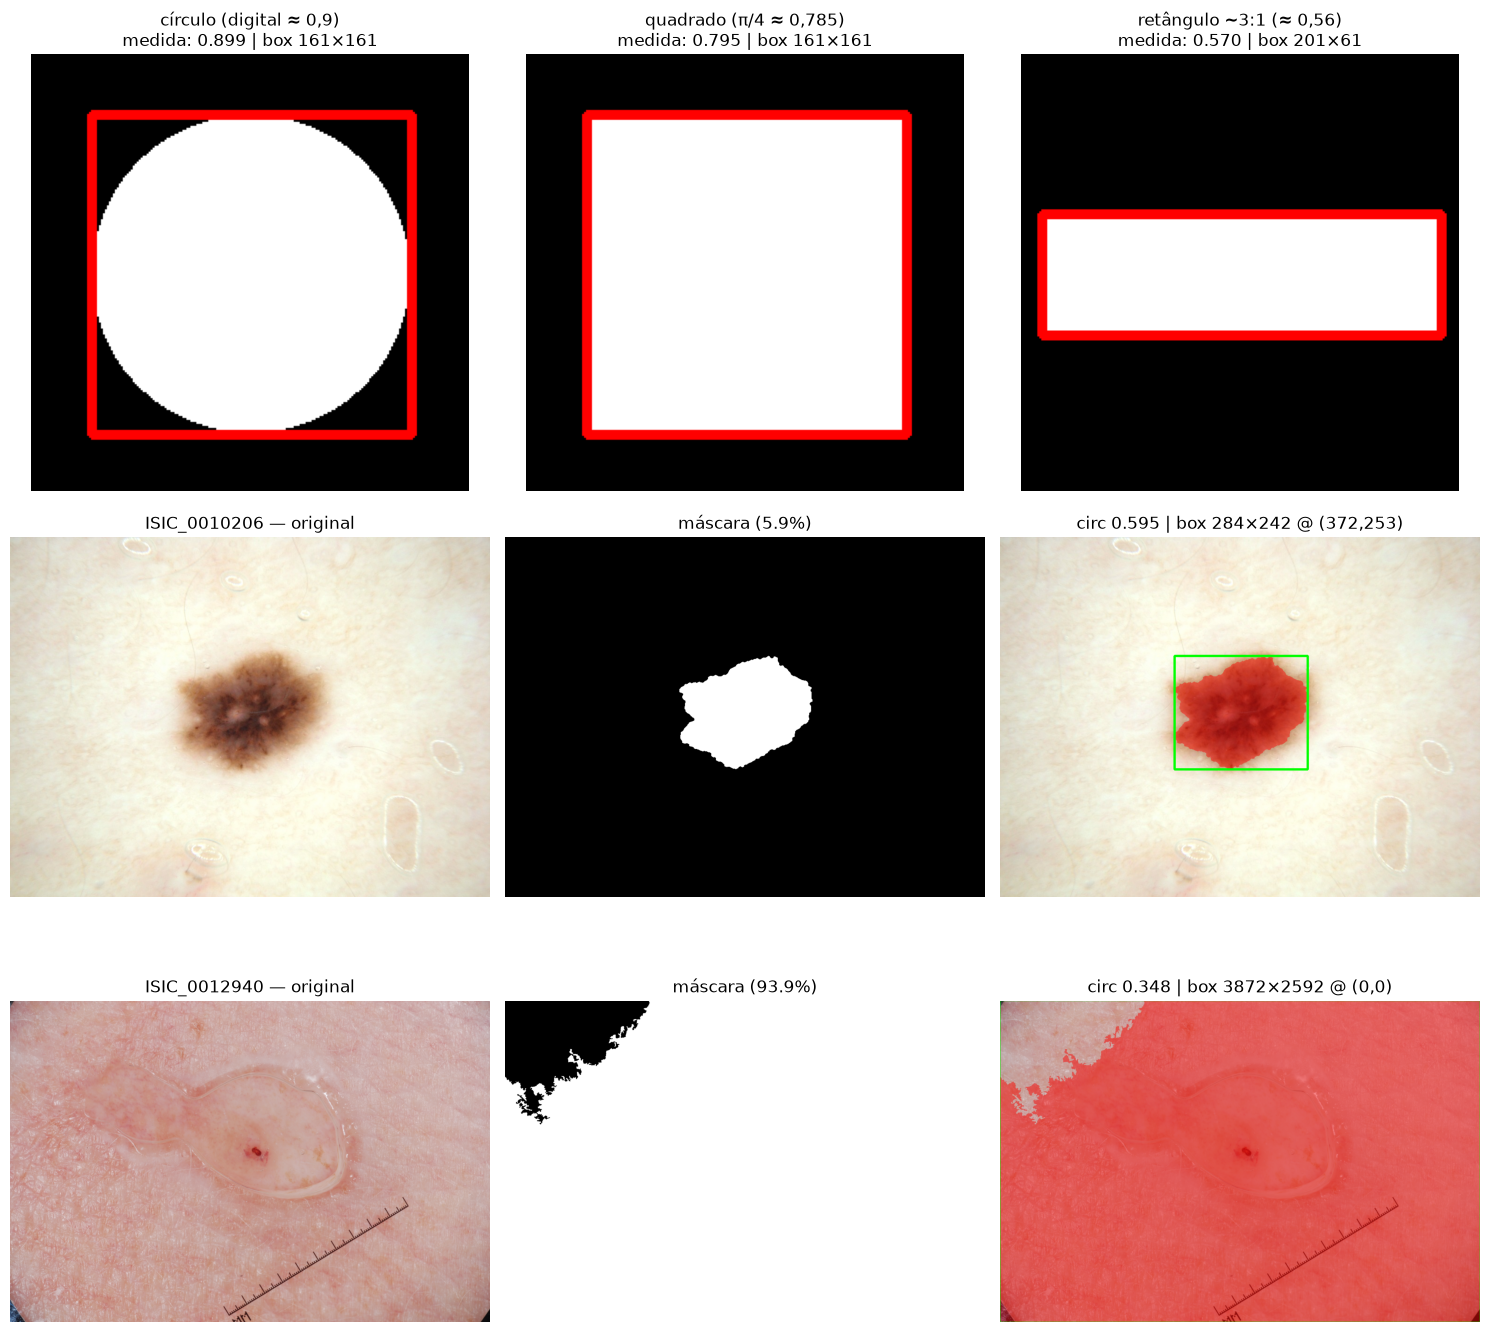

In [3]:
# linha 1: formas sintéticas — a ordenação valida a métrica (círculo > quadrado > retângulo)
formas = {}
c = np.zeros((220, 220), dtype=np.uint8); cv2.circle(c, (110, 110), 80, 255, -1)
formas["círculo (digital ≈ 0,9)"] = c
q = np.zeros((220, 220), dtype=np.uint8); cv2.rectangle(q, (30, 30), (190, 190), 255, -1)
formas["quadrado (π/4 ≈ 0,785)"] = q
r = np.zeros((220, 220), dtype=np.uint8); cv2.rectangle(r, (10, 80), (210, 140), 255, -1)
formas["retângulo ~3:1 (≈ 0,56)"] = r

fig, axes = plt.subplots(3, 3, figsize=(15, 14))
for j, (tit, msk_f) in enumerate(formas.items()):
    circ = circularidade(area_pixels(msk_f), perimetro(maior_contorno(msk_f)))
    x, y, w, h = bounding_box(msk_f)
    painel = cv2.cvtColor(msk_f, cv2.COLOR_GRAY2RGB)
    cv2.rectangle(painel, (x, y), (x + w, y + h), (255, 0, 0), 3)
    axes[0, j].imshow(painel)
    axes[0, j].set_title(f"{tit}\nmedida: {circ:.3f} | box {w}×{h}")
    axes[0, j].axis("off")

for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"], start=1):
    img = carregar_imagem(PASTA_IMAGENS / nome)
    cinza = para_cinza(img)
    msk = pos_processar(binarizar(cinza, otsu(cinza), invertida=True))
    nome_curto = Path(nome).stem
    circ = circularidade(area_pixels(msk), perimetro(maior_contorno(msk)))
    x, y, w, h = bounding_box(msk)
    painel = sobrepor(img, msk)
    cv2.rectangle(painel, (x, y), (x + w, y + h), (0, 255, 0), 4)
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{nome_curto} — original")
    axes[i, 1].imshow(msk, cmap="gray")
    axes[i, 1].set_title(f"máscara ({msk.mean()/255*100:.1f}%)")
    axes[i, 2].imshow(painel)
    axes[i, 2].set_title(f"circ {circ:.3f} | box {w}×{h} @ ({x},{y})")
    for ax in axes[i]:
        ax.axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "contornos" / "circularidade_box.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)